# Analytical Solution: Elastic–Plastic Tensile Bar

This notebook calculates the right-end axial stress, axial and equivalent plastic strain, and force–displacement response for the tensile-bar example.

A consistent **mm, s, N, tonne** unit system is used. The reference assumes small strain, uniform uniaxial tension, monotonic loading and linear isotropic hardening. It is not an exact three-dimensional solution near the clamp.

## Problem Data

- Length along global $x$: $L=100\,\mathrm{mm}$
- Cross-section: $b=h=10\,\mathrm{mm}$
- Right-end displacement: $u=0.5\,\mathrm{mm}$
- Young's modulus: $E=210000\,\mathrm{MPa}$; Poisson's ratio: $\nu=0.3$
- Initial yield stress: $\sigma_y=250\,\mathrm{MPa}$
- Second plastic-data point: $350\,\mathrm{MPa}$ at equivalent plastic strain $0.01$

The right end can contract transversely. The hardening slope is defined with respect to plastic strain, not total strain.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L = 100.0           # Length [mm]
b = h = 10.0        # Cross-section dimensions [mm]
u_right = 0.5       # Prescribed displacement [mm]
E = 210_000.0       # Young's modulus [MPa]
nu = 0.3
sigma_y = 250.0     # Initial yield stress [MPa]
sigma_2 = 350.0     # Second hardening stress [MPa]
ep_2 = 0.01         # Equivalent plastic strain [-]
A = b * h
H = (sigma_2 - sigma_y) / ep_2
Et = E * H / (E + H)
u_y = L * sigma_y / E
F_y = A * sigma_y

print(f"Area = {A:.2f} mm²")
print(f"Plastic hardening slope H = {H:.2f} MPa")
print(f"Post-yield tangent modulus Et = {Et:.2f} MPa")
print(f"Yield displacement = {u_y:.6f} mm")
print(f"Yield force = {F_y:.2f} N")

Area = 100.00 mm²
Plastic hardening slope H = 10000.00 MPa
Post-yield tangent modulus Et = 9545.45 MPa
Yield displacement = 0.119048 mm
Yield force = 25000.00 N


## 1. Right-End Axial Stress and Plastic Strain

The uniform total axial strain is $\varepsilon_{xx}=u/L$. The uniaxial strain decomposition and post-yield hardening law are

$$\varepsilon_{xx}=\frac{\sigma_{xx}}{E}+\varepsilon^p_{xx},\qquad \sigma_{xx}=\sigma_y+H\varepsilon^p_{xx}.$$

Solving gives

$$\boxed{\varepsilon^p_{xx}=\max\left(0,\frac{E(u/L)-\sigma_y}{E+H}\right)},\qquad
\boxed{\sigma_{xx}=E\left(\frac{u}{L}-\varepsilon^p_{xx}\right)}.$$

Under monotonic uniaxial tension, equivalent plastic strain equals the positive axial plastic strain: $\bar\varepsilon^p=\varepsilon^p_{xx}$.

In [2]:
eps_total = u_right / L
eps_p = max(0.0, (E * eps_total - sigma_y) / (E + H))
sigma_xx = E * (eps_total - eps_p)
eps_elastic = sigma_xx / E
peeq = eps_p
F_final = A * sigma_xx

assert np.isclose(eps_total, eps_elastic + eps_p)
assert np.isclose(sigma_xx, sigma_y + H * eps_p)
assert 0.0 < peeq < ep_2

print(f"Total axial strain = {eps_total:.8f} ({100*eps_total:.4f} %)")
print(f"Elastic axial strain = {eps_elastic:.8f}")
print(f"Axial plastic strain = {eps_p:.8f} ({100*eps_p:.4f} %)")
print(f"Equivalent plastic strain PEEQ = {peeq:.8f}")
print(f"Right-end stress SXX / S11 = {sigma_xx:.4f} MPa")
print(f"Final tensile force = {F_final:.4f} N")

Total axial strain = 0.00500000 (0.5000 %)
Elastic axial strain = 0.00136364
Axial plastic strain = 0.00363636 (0.3636 %)
Equivalent plastic strain PEEQ = 0.00363636
Right-end stress SXX / S11 = 286.3636 MPa
Final tensile force = 28636.3636 N


At $u=0.5\,\mathrm{mm}$,

$$\boxed{\sigma_{xx}=286.36\,\mathrm{MPa}},\qquad
\boxed{\varepsilon^p_{xx}=\mathrm{PEEQ}=0.00363636\;(0.3636\%)}.$$

Plastic strain is the irreversible part of the strain, not the total strain $0.005$. Stress exceeds the initial yield stress because the material hardens. Compare with right-end-adjacent element results; the fully clamped left face creates local three-dimensional effects, so the uniform solution is a reference rather than an exact FE prediction.

## 2. Force–Displacement Behaviour

Using the original area $A=100\,\mathrm{mm^2}$,

$$F(u)=\begin{cases}\dfrac{AE}{L}u,&u\leq u_y,\\[4pt]
F_y+\dfrac{AE_t}{L}(u-u_y),&u>u_y,\end{cases}
\qquad E_t=\frac{EH}{E+H}.$$

The initial elastic response is linear. Yield starts at $u_y=0.11905\,\mathrm{mm}$ and $F_y=25000\,\mathrm{N}$. Afterwards the force still increases, but with a much smaller slope due to plastic deformation and hardening. The final force is $28636.36\,\mathrm{N}$.

For FE comparison, use mean right-end $U_1$ and negative summed left-end $RF_1$. Do not sum reaction forces over time increments.

Elastic stiffness = 210000.00 N/mm
Post-yield stiffness = 9545.45 N/mm


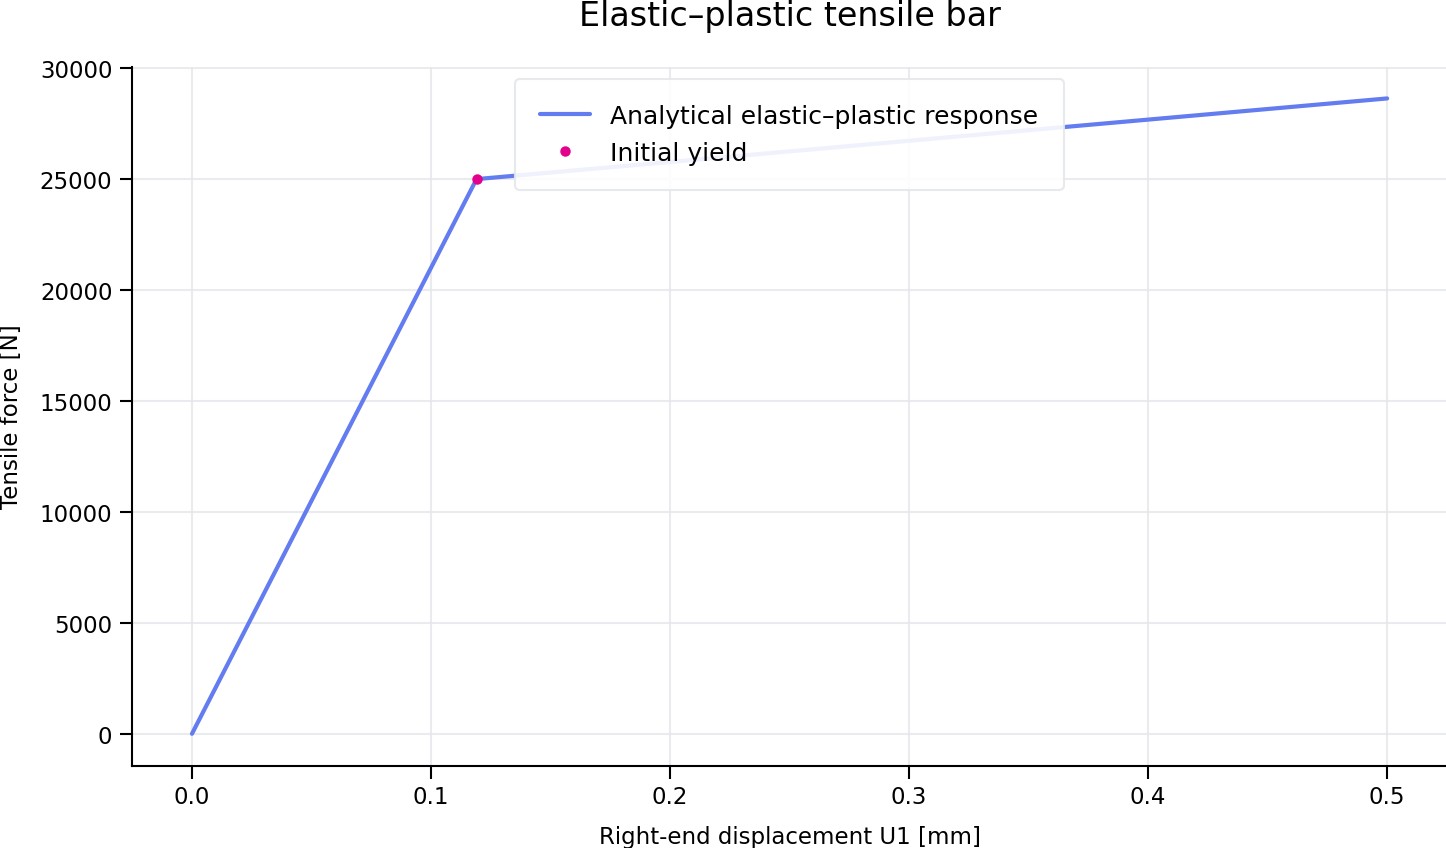

In [3]:
u = np.sort(np.unique(np.r_[np.linspace(0.0, u_right, 301), u_y]))
eps = u / L
eps_p_curve = np.maximum(0.0, (E * eps - sigma_y) / (E + H))
force = A * E * (eps - eps_p_curve)

# Check against an independent piecewise expression.
force_check = np.where(u <= u_y, A * E / L * u,
                       F_y + A * Et / L * (u - u_y))
assert np.allclose(force, force_check)

fig, ax = plt.subplots()
ax.plot(u, force, label="Analytical elastic–plastic response")
ax.plot(u_y, F_y, "o", label="Initial yield")
ax.set_xlabel("Right-end displacement U1 [mm]")
ax.set_ylabel("Tensile force [N]")
ax.set_title("Elastic–plastic tensile bar")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Elastic stiffness = {A * E / L:.2f} N/mm")
print(f"Post-yield stiffness = {A * Et / L:.2f} N/mm")

## Summary

| Analytical quantity | Final value |
|---|---:|
| Right-end displacement $U_1$ | 0.5 mm |
| Total axial strain | 0.005 |
| Axial stress $S_{11}=\sigma_{xx}$ | 286.36 MPa |
| Axial plastic strain | 0.00363636 |
| Equivalent plastic strain PEEQ | 0.00363636 |
| Tensile force | 28636.36 N |

These are small-strain analytical reference values, not extracted simulation results. The analytical strain assumes uniform extension along the bar.